In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

(x_train,y_train),(x_test,y_test)=tf.keras.datasets.fashion_mnist.load_data()

x_train=x_train.reshape(-1,784)/255.0
x_test=x_test.reshape(-1,784)/255.0

x_train,x_val=x_train[5000:],x_train[:5000]
y_train,y_val=y_train[5000:],y_train[:5000]

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [2]:
def create_model(init):
    model=tf.keras.Sequential([
        tf.keras.layers.Input(shape=(784,)),
        tf.keras.layers.Dense(256,activation='relu',kernel_initializer=init),
        tf.keras.layers.Dense(256,activation='relu',kernel_initializer=init),
        tf.keras.layers.Dense(256,activation='relu',kernel_initializer=init),
        tf.keras.layers.Dense(256,activation='relu',kernel_initializer=init),
        tf.keras.layers.Dense(10,activation='softmax')
    ])
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

In [3]:
initializers={
    'Small Random':tf.keras.initializers.RandomNormal(stddev=0.01),
    'Xavier':tf.keras.initializers.GlorotNormal(),
    'He':tf.keras.initializers.HeNormal()
}

results={}

for name,init in initializers.items():
    model=create_model(init)
    history=model.fit(x_train,y_train,epochs=3,batch_size=128,
                      validation_data=(x_val,y_val),verbose=1)
    results[name]=history
    print(name,"Validation Accuracy:",
          model.evaluate(x_val,y_val,verbose=0)[1]*100)

Epoch 1/3
430/430 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.7017 - loss: 0.7822 - val_accuracy: 0.8118 - val_loss: 0.5047
Epoch 2/3
430/430 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.8339 - loss: 0.4540 - val_accuracy: 0.8592 - val_loss: 0.3971
Epoch 3/3
430/430 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.8625 - loss: 0.3786 - val_accuracy: 0.8594 - val_loss: 0.3778
Small Random Validation Accuracy: 85.93999743461609
Epoch 1/3
430/430 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.8154 - loss: 0.5104 - val_accuracy: 0.8608 - val_loss: 0.3775
Epoch 2/3
430/430 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.8661 - loss: 0.3658 - val_accuracy: 0.8694 - val_loss: 0.3584
Epoch 3/3
430/430 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.8772 - loss: 0.3305 - val_accuracy: 0.8736 - val_loss: 0.3520
Xavier Validation Accuracy: 87.36000061035156
Epoch 1/3
430/430 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - accuracy: 0.8192 - loss: 0.5031 - val_accuracy: 0.8556 - val_loss: 0.3948
Epoc

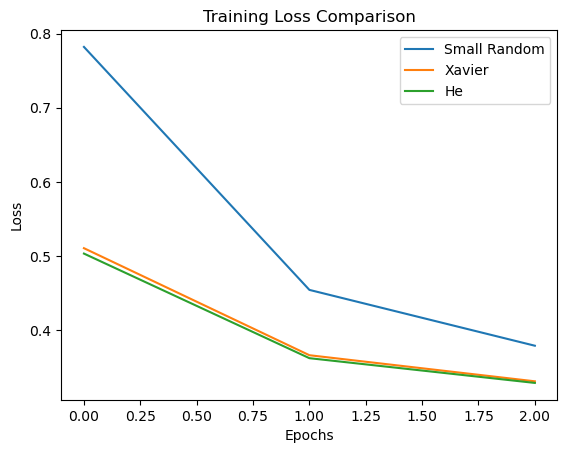

In [4]:
for name,h in results.items():
    plt.plot(h.history['loss'],label=name)

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training Loss Comparison')
plt.legend()
plt.show()

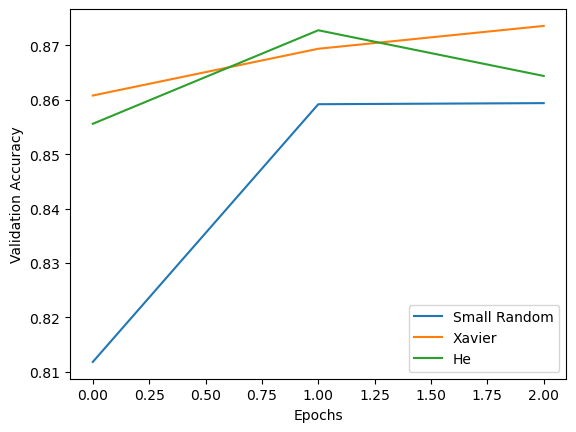

In [5]:
for name,h in results.items():
    plt.plot(h.history['val_accuracy'],label=name)

plt.xlabel('Epochs')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.show()

In [6]:
for name,init in initializers.items():
    model=create_model(init)
    x=tf.convert_to_tensor(x_train[:128],dtype=tf.float32)
    y=tf.convert_to_tensor(y_train[:128])

    with tf.GradientTape() as tape:
        loss=tf.reduce_mean(
            tf.keras.losses.sparse_categorical_crossentropy(y,model(x)))
    grads=tape.gradient(loss,model.trainable_variables)

    print(name,[round(float(tf.norm(g)),3) for g in grads if g is not None])

Small Random [0.002, 0.0, 0.002, 0.001, 0.002, 0.012, 0.002, 0.1, 0.0, 0.077]
Xavier [0.707, 0.05, 0.448, 0.062, 0.425, 0.088, 0.372, 0.103, 0.26, 0.084]
He [1.698, 0.132, 0.986, 0.137, 0.884, 0.118, 0.91, 0.11, 0.903, 0.101]


In [7]:
model=create_model(tf.keras.initializers.HeNormal())
model.fit(x_train,y_train,epochs=3,batch_size=128,verbose=0)
print("Test Accuracy:",model.evaluate(x_test,y_test)[1]*100)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8689 - loss: 0.3611
Test Accuracy: 86.89000010490417
